# What the images show: CLIP image topics, linked to replication, graduation and actors

Notebooks 01–03 treated an image as a hash: identical or near-identical artwork. This notebook asks
what the images *depict*, using CLIP, and links that to everything found so far.

**Method: Steffen (ICWSM 2025), "More than Memes: A Multimodal Topic Modeling Approach to
Conspiracy Theories on Telegram"**:

- images (and token texts) are embedded with sentence-transformers' **`clip-ViT-B-32`**;
- **image topics**: BERTopic on the CLIP image embeddings with its default UMAP/HDBSCAN settings;
  topic keywords come from **captions** generated by `nlpconnect/vit-gpt2-image-captioning`;
- **multimodal topics**: BERTopic on the average of a token's image and text embeddings;
- topic models of different modalities are compared with the paper's **symmetry ratio** (document
  overlap): a topic's best match in the other model must point back to it.

Scale adaptations, because the paper modelled ~40k messages and we have 2.7M distinct images:

- topics are **fitted on a random sample of 100k distinct images** and every other image is then
  assigned to the nearest topic centroid in CLIP space (or left as an outlier when it is far from
  every centroid);
- `min_topic_size = 50` instead of the paper's 20, keeping roughly the same share of the corpus per
  minimum topic (20 / 40k ≈ 50 / 100k);
- UMAP gets a fixed `random_state` (reproducibility) and the c-TF-IDF vectorizer drops English stop
  words (captions are full of "a", "of", "with");
- besides the caption keywords (the paper's representation), each image topic also gets keywords
  from the **names of the tokens** using its images. Captions describe what is drawn ("suit, tie,
  flag"); names say what the token is about ("trump, president"). Figures use the name keywords.

Embeddings and captions come from `python -m crypto_analysis.clip_embeddings {images,texts,captions}`.
Outcome and windows follow notebooks 02–03: graduation within 24 h, last two launch days dropped.

## Setup

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice on import

from bertopic import BERTopic  # noqa: E402
from hdbscan import HDBSCAN
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import torch
from umap import UMAP

from crypto_analysis.clip_embeddings import load_embeddings, token_text, topic_sample
from crypto_analysis.datalake import build_token_flags, connect
from crypto_analysis.gallery import load_images, names_for, show_grid
from crypto_analysis.image_features import multi_index_pairs
from crypto_analysis.plotting import (
    BLUE_RAMP,
    COLORS,
    FIG_4x3,
    FIG_6x4,
    GOLD,
    RED_RAMP,
    ROLE_COLORS,
    ROLE_ORDER,
    alluvial,
    ascii_label,
    count_label,
    density_area,
    dumbbell,
    forest,
    forest_by_row,
    image_treemap,
    pct_label,
    raincloud,
    rate_series,
    ridgeline,
    save_figure,
    set_latex_style,
    tex_escape,
)
from crypto_analysis.topic_alignment import symmetry_ratio

USE_TEX = set_latex_style()
warnings.filterwarnings("ignore", message="Glyph .* missing from font")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

In [2]:
CLIP_DIR = Path("../data/clip")  # output of crypto_analysis.clip_embeddings
FEATURES_DIR = Path("../data/image_features")  # pHash per image (notebook 02)
FIG_DIR = Path("../reports/figures/04_clip_image_semantics")
SAVE_FIGS = True  # write every figure to FIG_DIR as PDF (for LaTeX) + PNG

# Optional: text topics from the BERTopic run on names + descriptions, as a Parquet file with
# columns `mint` and `topic` (and optionally `label`). Section 7 aligns them when the file exists.
TEXT_TOPICS = Path("../data/text_topics.parquet")

SAMPLE_N = 100_000
MIN_TOPIC_SIZE = 50
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

con = connect(threads=8, memory_limit="16GB")
build_token_flags(con)


def q(sql):
    return con.execute(sql).df()


def save(fig, name):
    if SAVE_FIGS:
        save_figure(fig, FIG_DIR / name)


BLUE, RED, AQUA = COLORS["blue"], COLORS["red"], COLORS["aqua"]
INK, INK_2, MUTED = COLORS["ink"], COLORS["ink_secondary"], COLORS["muted"]

In [3]:
img_keys, img_emb = load_embeddings(CLIP_DIR / "images", "sha256")
txt_keys, txt_emb = load_embeddings(CLIP_DIR / "texts", "mint")
img_index, txt_index = pd.Index(img_keys), pd.Index(txt_keys)
print(f"image embeddings: {img_emb.shape}, text embeddings: {txt_emb.shape}")

tok = q('''
WITH c AS (SELECT coin_creator, count(*) AS creator_tokens FROM token_flags GROUP BY 1)
SELECT f.mint, f.sha256, f.day, f.created_at, f.coin_creator, f.role, f.graduated, f.grad_fast, f.n_tokens,
       c.creator_tokens
FROM token_flags f JOIN c USING (coin_creator)
WHERE f.day < (SELECT max(day) - 1 FROM token_flags)
''')
tok["img_row"] = img_index.get_indexer(tok.sha256)
tok["txt_row"] = txt_index.get_indexer(tok.mint)
tok["creator_size"] = pd.cut(tok.creator_tokens, [0, 1, 10, 100, np.inf], labels=["1", "2-10", "11-100", "> 100"])
print(f"{len(tok):,} tokens; with an image embedding: {(tok.img_row >= 0).mean():.1%}; "
      f"with a text embedding: {(tok.txt_row >= 0).mean():.1%}")

image embeddings: (2695112, 512), text embeddings: (5212365, 512)


5,114,901 tokens; with an image embedding: 100.0%; with a text embedding: 100.0%


## 1. Image topics (BERTopic on CLIP image embeddings)

Fitted on the 100k-image sample with the captions as documents (for the keywords), exactly as the
paper's image-only model.

In [4]:
sample = topic_sample(img_keys, SAMPLE_N, SEED)
captions = pd.read_parquet(CLIP_DIR / "captions.parquet").drop_duplicates("sha256").set_index("sha256").caption
sample = np.array([s for s in sample if s in captions.index])
X = img_emb[img_index.get_indexer(sample)].astype(np.float32)
docs = captions.reindex(sample).tolist()
print(f"{len(sample):,} sampled images with captions, e.g.:", docs[:3])


def make_topic_model():
    '''BERTopic with its defaults (as in the paper), seeded, and English stop words removed.'''
    return BERTopic(
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=MIN_TOPIC_SIZE, metric="euclidean",
                              cluster_selection_method="eom", prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words="english"),
        min_topic_size=MIN_TOPIC_SIZE,
    )


image_model = make_topic_model()
sample_topics, _ = image_model.fit_transform(docs, embeddings=X)
sample_topics = np.asarray(sample_topics)
info = image_model.get_topic_info()
print(f"{(info.Topic >= 0).sum()} image topics; outliers: {(sample_topics == -1).mean():.1%} of the sample")


def topic_label(model, t, k=3):
    if t == -1:
        return "outlier"
    return " · ".join(w for w, _ in model.get_topic(t)[:k])


caption_labels = {t: topic_label(image_model, t) for t in info.Topic}

# Second representation: c-TF-IDF over the token names using each sampled image
name_of = names_for(con, sample)
name_docs = [str(name_of.get(s, "")) for s in sample]
image_model.update_topics(name_docs, vectorizer_model=CountVectorizer(stop_words="english", min_df=2))
image_labels = {t: topic_label(image_model, t) for t in info.Topic}
display(pd.DataFrame({"tokens in sample": info.set_index("Topic").Count,
                      "caption keywords": pd.Series(caption_labels),
                      "name keywords": pd.Series(image_labels)}).head(20))

100,000 sampled images with captions, e.g.: ['a person holding a flag on a flag pole', 'a man in a suit and tie standing in front of a wall', 'a sign with a bird on it']


207 image topics; outliers: 46.0% of the sample


,tokens in sample,caption keywords,name keywords
-1,46042,outlier,outlier
0,3407,dog · collar · wearing,dog · puppy · doge
1,3046,cat · sitting · laying,cat · cats · kitty
2,2197,suit · tie · flag,trump · donald · trumps
3,1683,cartoon · character · animal,pepe · frog · apu
4,1572,stuffed · animal · heart,inu · doge · cat
5,1536,bird · duck · beak,penguin · duck · bird
6,1472,blurry · background · street,labs · ai · network
7,1010,photo · clock · keyboard,fartcoin · rapecoin · pisscoin
8,958,statue · sword · costume,whale · white · trout


### Every image gets a topic

Each topic's centroid is the normalised mean CLIP embedding of its sample members. Every image is
assigned to the most similar centroid, unless that similarity is below the 5th percentile of the
members' similarity to their own centroid; then it is an outlier (-1).

In [5]:
topic_ids = np.array(sorted(t for t in set(sample_topics) if t != -1))
C = np.stack([X[sample_topics == t].mean(axis=0) for t in topic_ids])
C /= np.linalg.norm(C, axis=1, keepdims=True)
own_sim = np.array([X[i] @ C[np.searchsorted(topic_ids, t)] for i, t in enumerate(sample_topics) if t != -1])
threshold = np.percentile(own_sim, 5)

Ct = torch.from_numpy(C).to(DEVICE, dtype=torch.float16)
best_topic, best_sim = np.empty(len(img_keys), dtype=int), np.empty(len(img_keys), dtype=np.float32)
for s in range(0, len(img_keys), 200_000):
    sims = torch.from_numpy(img_emb[s:s + 200_000]).to(DEVICE) @ Ct.T
    v, k = sims.max(dim=1)
    best_topic[s:s + 200_000], best_sim[s:s + 200_000] = topic_ids[k.cpu().numpy()], v.float().cpu().numpy()
img_topic = np.where(best_sim >= threshold, best_topic, -1)

in_sample = img_index.get_indexer(sample)
agree = (img_topic[in_sample] == sample_topics)[sample_topics != -1].mean()
print(f"Similarity threshold {threshold:.3f}; images assigned to a topic: {(img_topic != -1).mean():.1%}")
print(f"Sanity check: centroid assignment agrees with HDBSCAN on {agree:.1%} of clustered sample images")

tok["image_topic"] = np.where(tok.img_row >= 0, img_topic[tok.img_row.clip(lower=0)], -1)
tok["image_label"] = tok.image_topic.map(image_labels)

pd.DataFrame({"sha256": img_keys, "image_topic": img_topic, "similarity": best_sim}).to_parquet(
    CLIP_DIR / "image_topics.parquet", index=False)
pd.DataFrame({"topic": list(image_labels), "name_keywords": list(image_labels.values()),
              "caption_keywords": [caption_labels[t] for t in image_labels]}).to_csv(
    CLIP_DIR / "image_topic_labels.csv", index=False)

Similarity threshold 0.674; images assigned to a topic: 92.3%
Sanity check: centroid assignment agrees with HDBSCAN on 86.3% of clustered sample images


## 2. The image-topic landscape

**Atlas.** A 2-D UMAP map of 30k sampled images (grey), with each large topic's most central image
placed at the topic's position.

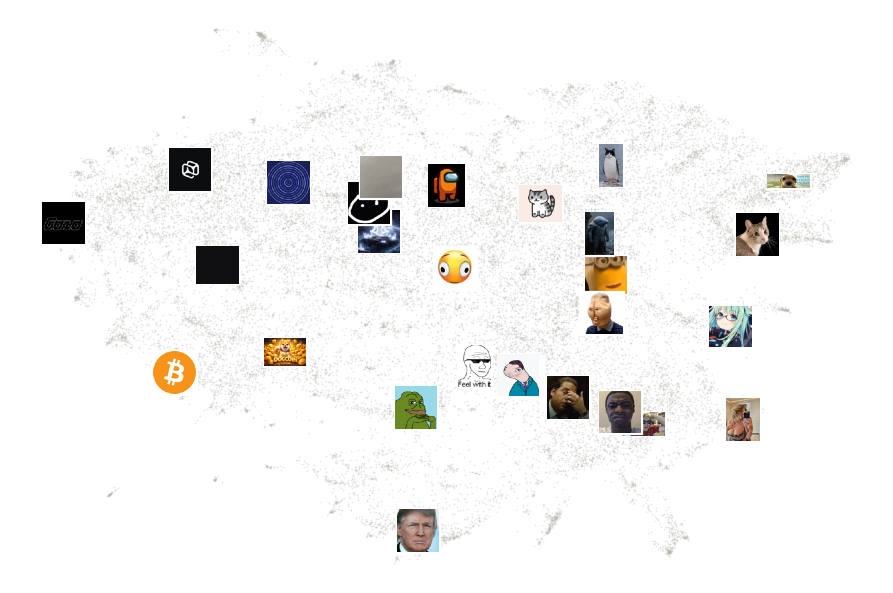

In [6]:
topic_tokens = tok[tok.image_topic != -1].image_topic.value_counts()
medoid = {}
for t in topic_ids:
    members = np.flatnonzero(sample_topics == t)
    medoid[t] = sample[members[np.argmax(X[members] @ C[np.searchsorted(topic_ids, t)])]]

sub = np.random.default_rng(SEED).choice(len(sample), size=min(30_000, len(sample)), replace=False)
xy = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(X[sub])

fig, ax = plt.subplots(figsize=FIG_6x4)
ax.scatter(xy[:, 0], xy[:, 1], s=0.6, color=MUTED, alpha=0.35, lw=0)
big = topic_tokens.head(28).index
thumbs = load_images(con, [medoid[t] for t in big])
for t in big:
    pts = xy[sample_topics[sub] == t]
    if len(pts) < 5:
        continue
    cx, cy = np.median(pts, axis=0)
    img = thumbs[medoid[t]].convert("RGB")
    img.thumbnail((64, 64))
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(img), zoom=0.32), (cx, cy), frameon=True,
                                 bboxprops={"edgecolor": "white", "linewidth": 0.6}, pad=0.05))
ax.axis("off")
save(fig, "topic_atlas")

**Treemap.** The 40 image topics with the most tokens; tile area is proportional to the number of
tokens, the image is the topic's most central one, and the badge (gold when the topic's graduation
rate is above the overall rate) gives the topic's keywords.

,tokens,k,rate,label
image_topic,,,,
6,"179,350","1,938",1.08%,labs · ai · network
0,"172,916","1,444",0.84%,dog · puppy · doge
1,"155,700","1,210",0.78%,cat · cats · kitty
4,"138,106","1,584",1.15%,inu · doge · cat
2,"97,309","1,325",1.36%,trump · donald · trumps
3,"94,222",889,0.94%,pepe · frog · apu
20,"86,734",700,0.81%,tung · shrek · sahur
14,"76,802",867,1.13%,wojak · brainlet · replacement
9,"74,899",405,0.54%,oi · jack · live


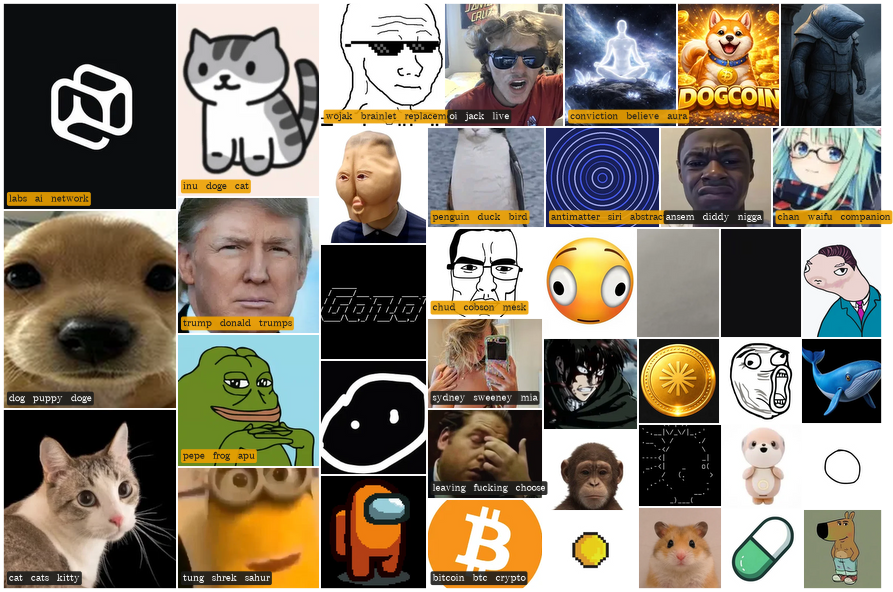

In [7]:
overall = tok.grad_fast.mean()
tstats = (tok[tok.image_topic != -1].groupby("image_topic").agg(tokens=("mint", "size"), k=("grad_fast", "sum"))
          .sort_values("tokens", ascending=False))
tstats["rate"] = tstats.k / tstats.tokens
tstats["label"] = tstats.index.map(image_labels)
display(tstats.head(25).style.format({"tokens": "{:,}", "k": "{:,}", "rate": "{:.2%}"}))

top40 = tstats.head(40)
fig, ax = plt.subplots(figsize=FIG_6x4)
image_treemap(ax, load_images(con, [medoid[t] for t in top40.index]), [medoid[t] for t in top40.index],
              top40.tokens, badges=[ascii_label(lbl, 26) for lbl in top40.label],
              gold=(top40.rate > overall).tolist(), min_badge_width=0.75)
save(fig, "topic_treemap")

## 3. Topics × graduation and replication

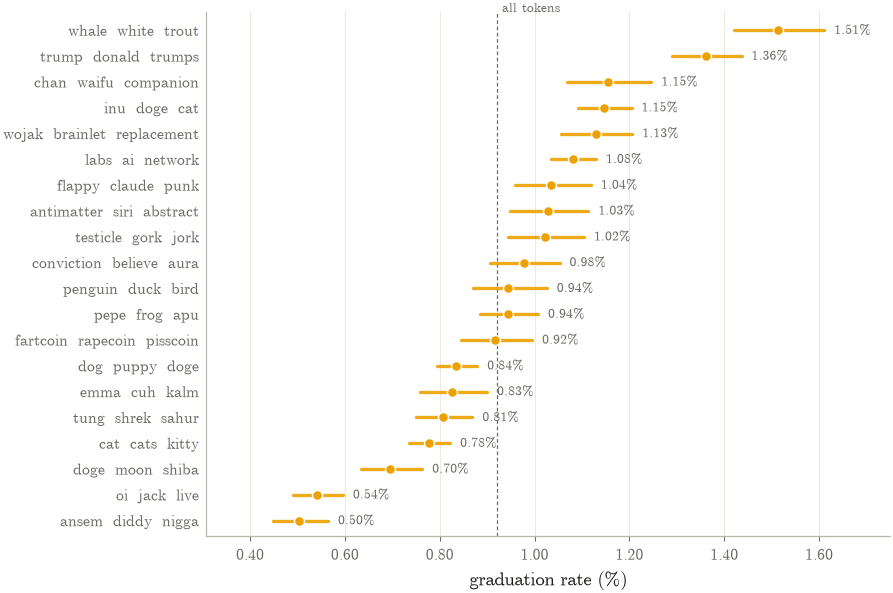

In [8]:
top20 = tstats.head(20).sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=FIG_6x4)
forest(ax, [ascii_label(lbl, 30) for lbl in top20.label],
       [rate_series("graduation", GOLD, top20.k, top20.tokens)], ref=overall, ref_label="all tokens")
ax.set_xlabel(pct_label("graduation rate"))
save(fig, "graduation_by_topic")

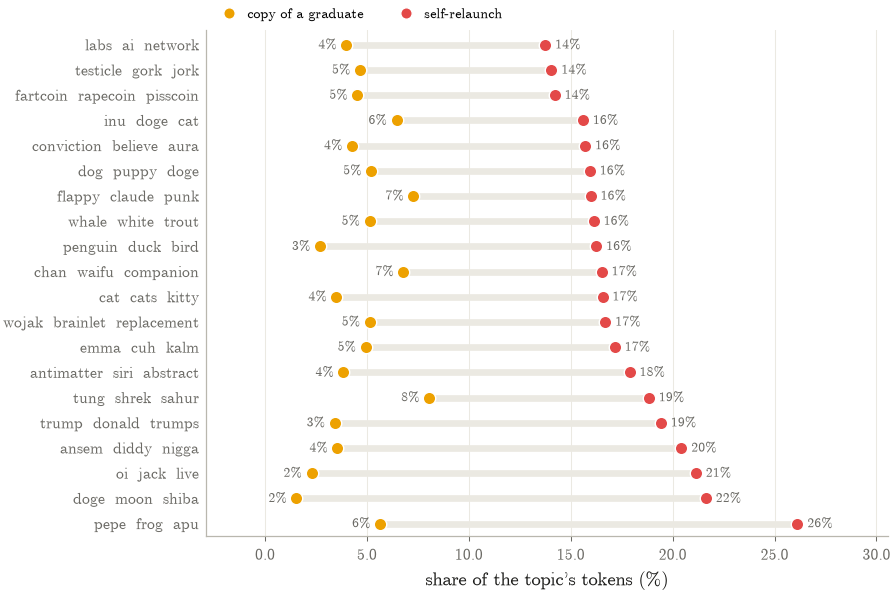

In [9]:
roles_by_topic = (tok[tok.image_topic.isin(top20.index)].groupby("image_topic").role.value_counts(normalize=True)
                  .unstack().reindex(top20.index).fillna(0))
order = roles_by_topic.sort_values("self-relaunch").index
fig, ax = plt.subplots(figsize=FIG_6x4)
dumbbell(ax, [ascii_label(image_labels[t], 30) for t in order], roles_by_topic.loc[order, "copy of a graduate"],
         roles_by_topic.loc[order, "self-relaunch"], left_label="copy of a graduate", right_label="self-relaunch",
         left_color=GOLD, right_color=RED, value_fmt="{:.0%}")
ax.set_xlabel(pct_label("share of the topic's tokens"))
save(fig, "topic_roles")

**Topic timelines.** When each of the 14 largest topics was popular: its share of all launches per
day (7-day mean), each ridge rescaled from its own minimum to its own peak, so the ridges show waves
of a theme rather than the overall launch volume.

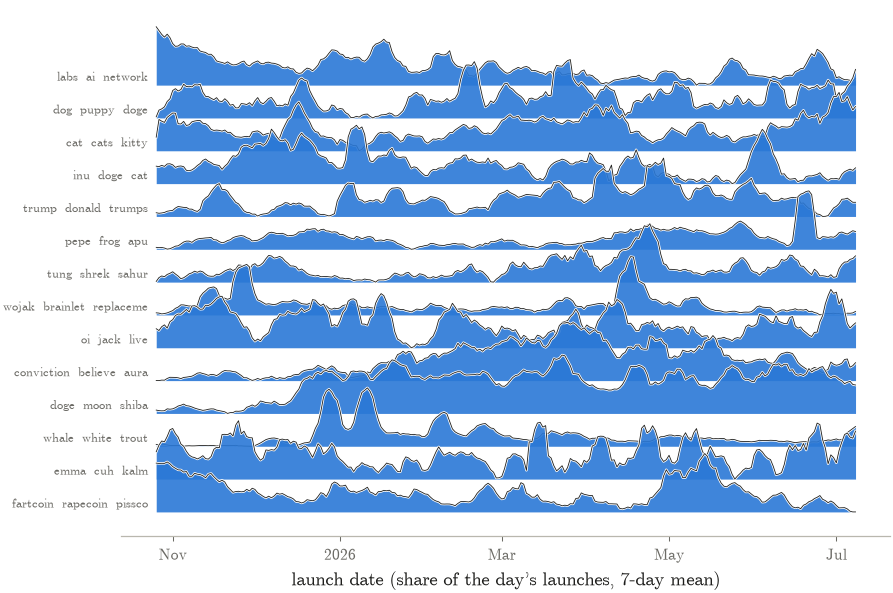

In [10]:
top14 = tstats.head(14).index
daily_total = tok.groupby("day").size()
fig, ax = plt.subplots(figsize=FIG_6x4)
for i, t in enumerate(top14):
    share = (tok[tok.image_topic == t].groupby("day").size().reindex(daily_total.index, fill_value=0) / daily_total)
    share = share.rolling(7, center=True, min_periods=1).mean()
    x = pd.to_datetime(share.index)
    v = share.to_numpy()
    y = (v - v.min()) / (v.max() - v.min()) * 1.6  # each ridge from its own minimum to its peak
    base, z = -i * 0.9, 2 * i
    ax.fill_between(x, base, base + y, color=BLUE, alpha=0.9, lw=0, zorder=z)
    ax.plot(x, base + y, color="white", lw=1.2, zorder=z + 1)
    ax.plot(x, base + y, color=INK, lw=0.4, zorder=z + 1)
    ax.text(x[0] - pd.Timedelta(days=3), base + 0.05, ascii_label(image_labels[t], 26), ha="right", va="bottom",
            fontsize=6, color=INK_2)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
locator = mdates.MonthLocator(bymonth=[1, 3, 5, 7, 9, 11])
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set_xlabel("launch date (share of the day's launches, 7-day mean)")
save(fig, "topic_timelines")

## 4. Does the image match the name?

CLIP puts images and texts in one space, so the cosine similarity between a token's image and its
"name. description" measures how well they match (CLIP similarities are typically 0.15–0.35).

,count,mean,std,min,25%,50%,75%,max
role,,,,,,,,
copy (other creator),1282877.0,0.254,0.044,-0.034,0.223,0.247,0.282,0.476
copy of a graduate,223866.0,0.247,0.044,0.108,0.218,0.238,0.269,0.462
original,2725509.0,0.267,0.047,0.051,0.231,0.262,0.299,0.501
self-relaunch,881368.0,0.257,0.046,0.031,0.223,0.248,0.286,0.475


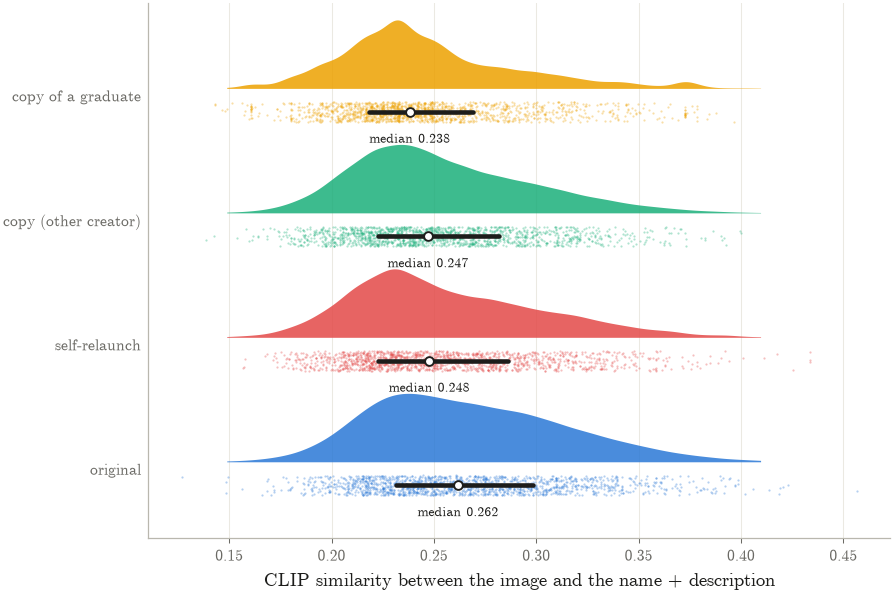

In [11]:
has = ((tok.img_row >= 0) & (tok.txt_row >= 0)).to_numpy()
align = np.full(len(tok), np.nan, dtype=np.float32)
idx = np.flatnonzero(has)
for s in range(0, len(idx), 500_000):
    part = idx[s:s + 500_000]
    a = torch.from_numpy(img_emb[tok.img_row.to_numpy()[part]]).to(DEVICE)
    b = torch.from_numpy(txt_emb[tok.txt_row.to_numpy()[part]]).to(DEVICE)
    align[part] = (a * b).sum(dim=1).float().cpu().numpy()
tok["img_text_sim"] = align
display(tok.groupby("role").img_text_sim.describe().round(3))

fig, ax = plt.subplots(figsize=FIG_6x4)
raincloud(ax, [(r, tok.loc[tok.role == r, "img_text_sim"].dropna(), ROLE_COLORS[r]) for r in ROLE_ORDER],
          bw=0.12, summary_fmt="median {:.3f}")
ax.set_xlabel("CLIP similarity between the image and the name + description")
save(fig, "alignment_by_role")

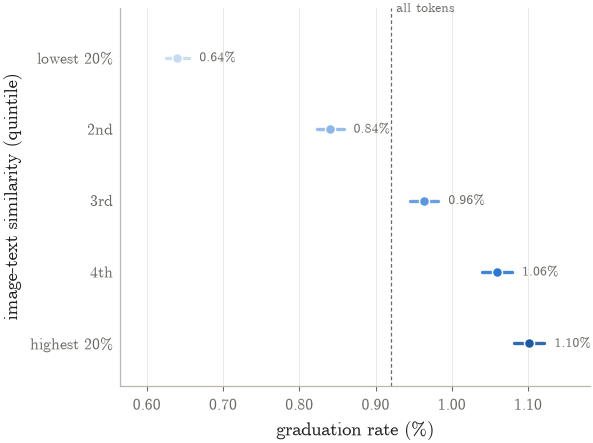

In [12]:
QUINTS = ["lowest 20%", "2nd", "3rd", "4th", "highest 20%"]
tok["align_q"] = pd.qcut(tok.img_text_sim, 5, labels=QUINTS)
aq = tok.groupby("align_q", observed=True).grad_fast.agg(k="sum", n="size").reindex(QUINTS)
fig, ax = plt.subplots(figsize=FIG_4x3)
forest_by_row(ax, QUINTS, aq.k, aq.n, BLUE_RAMP, ref=overall, ref_label="all tokens")
ax.set_xlabel(pct_label("graduation rate"))
ax.set_ylabel("image-text similarity (quintile)")
save(fig, "graduation_by_alignment")

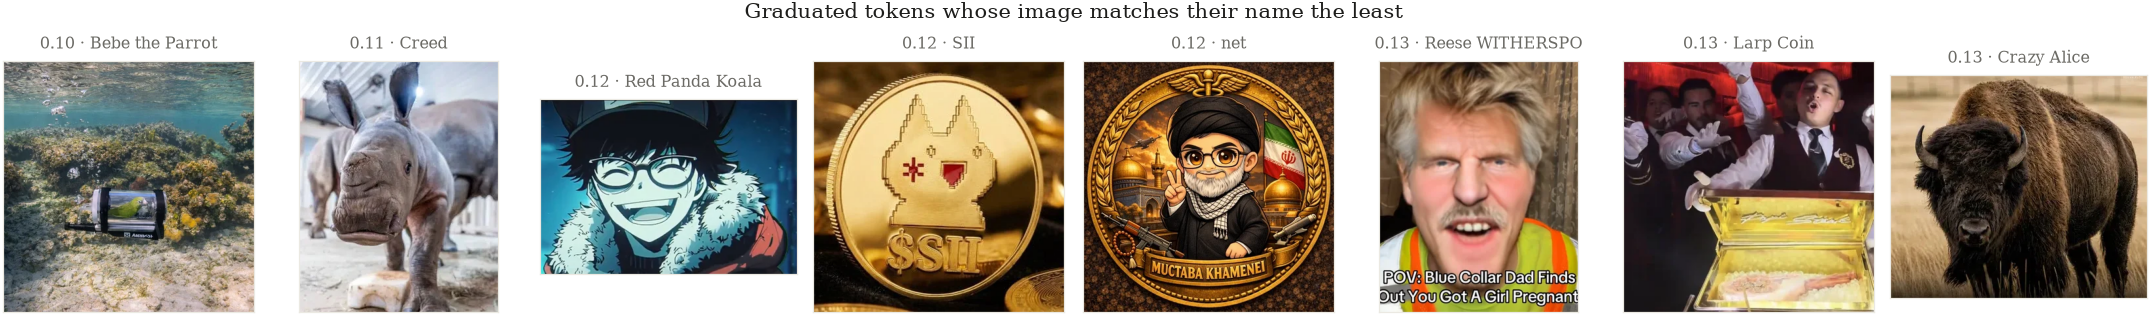

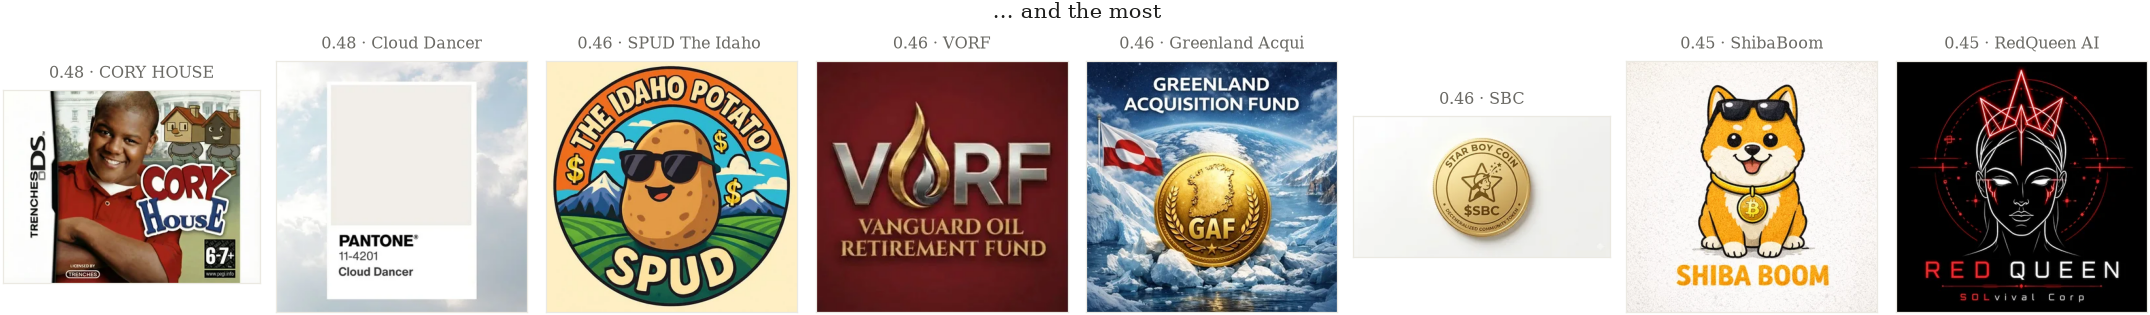

In [13]:
# Graduated tokens whose image and name agree the least and the most
g = tok[tok.graduated & tok.img_text_sim.notna()]
names = q(f'''SELECT mint, meta_name FROM token_metadata
             WHERE mint IN ({",".join("'" + m + "'" for m in pd.concat([g.nsmallest(8, "img_text_sim"), g.nlargest(8, "img_text_sim")]).mint)})''')
names = dict(zip(names.mint, names.meta_name))
for title, part, name in [("Graduated tokens whose image matches their name the least", g.nsmallest(8, "img_text_sim"), "align_low"),
                          ("... and the most", g.nlargest(8, "img_text_sim"), "align_high")]:
    fig = show_grid(con, part.sha256, [f"{a:.2f} · {names.get(m, '')}" for a, m in zip(part.img_text_sim, part.mint)],
                    suptitle=title)
    save(fig, name)

## 5. Semantic copies: same idea, different pixels

pHash (notebook 02) finds near-identical pixels. CLIP also finds images that show *the same thing*
redrawn, recoloured or re-posed. Within the 100k sample: each image's nearest neighbour by CLIP
cosine, compared with pHash near-duplicates (distance ≤ 4).

CLIP near-duplicate (cos >= 0.95),False,True
pHash near-duplicate (d <= 4),,
False,84.4%,6.0%
True,3.3%,6.3%


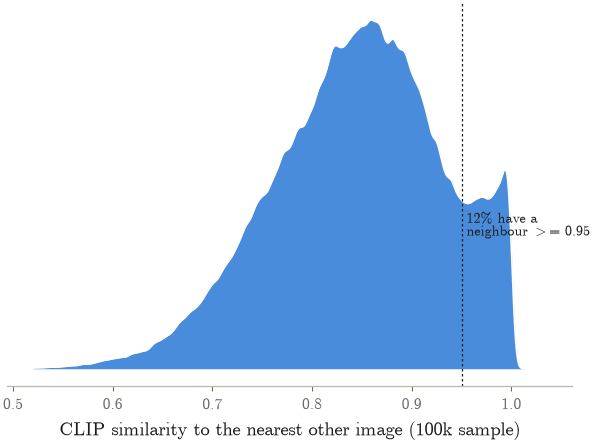

In [14]:
Xt = torch.from_numpy(X).to(DEVICE, dtype=torch.float16)
nn_sim, nn_idx = np.empty(len(X), dtype=np.float32), np.empty(len(X), dtype=int)
for s in range(0, len(X), 4096):
    sims = Xt[s:s + 4096] @ Xt.T
    sims[torch.arange(sims.shape[0]), torch.arange(s, s + sims.shape[0])] = -1  # ignore self
    v, k = sims.max(dim=1)
    nn_sim[s:s + 4096], nn_idx[s:s + 4096] = v.float().cpu().numpy(), k.cpu().numpy()

files = [p for p in sorted(FEATURES_DIR.glob("shard_*.parquet")) if not p.name.endswith(".errors.parquet")]
ph = pd.concat([pd.read_parquet(p, columns=["sha256", "phash"]) for p in files]).set_index("sha256").phash
sample_ph = ph.reindex(sample).to_numpy(np.uint64)
uniq, inv = np.unique(sample_ph, return_inverse=True)
pairs = multi_index_pairs(uniq, 4)
has_phash_dup = np.zeros(len(uniq), bool)
has_phash_dup[pairs.i] = has_phash_dup[pairs.j] = True
counts = np.bincount(inv)
phash_dup = has_phash_dup[inv] | (counts[inv] > 1)

CLIP_DUP = 0.95
clip_dup = nn_sim >= CLIP_DUP
table = pd.crosstab(pd.Series(phash_dup, name="pHash near-duplicate (d <= 4)"),
                    pd.Series(clip_dup, name=f"CLIP near-duplicate (cos >= {CLIP_DUP})"), normalize="all")
display(table.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=FIG_4x3)
grid, dens = density_area(ax, nn_sim, color=BLUE, bw=0.04, median=False)
ax.axvline(CLIP_DUP, color=INK, lw=0.6, ls=(0, (2, 2)))
ax.text(CLIP_DUP + 0.005, dens.max() * 0.45, tex_escape(f"{clip_dup.mean():.0%} have a\nneighbour >= {CLIP_DUP}"),
        ha="left", va="top", fontsize=6.8, color=INK)
ax.set_xlabel("CLIP similarity to the nearest other image (100k sample)")
save(fig, "clip_nn_similarity")

Sample images with a CLIP neighbour >= 0.95 but pHash distance > 16: 3.9%


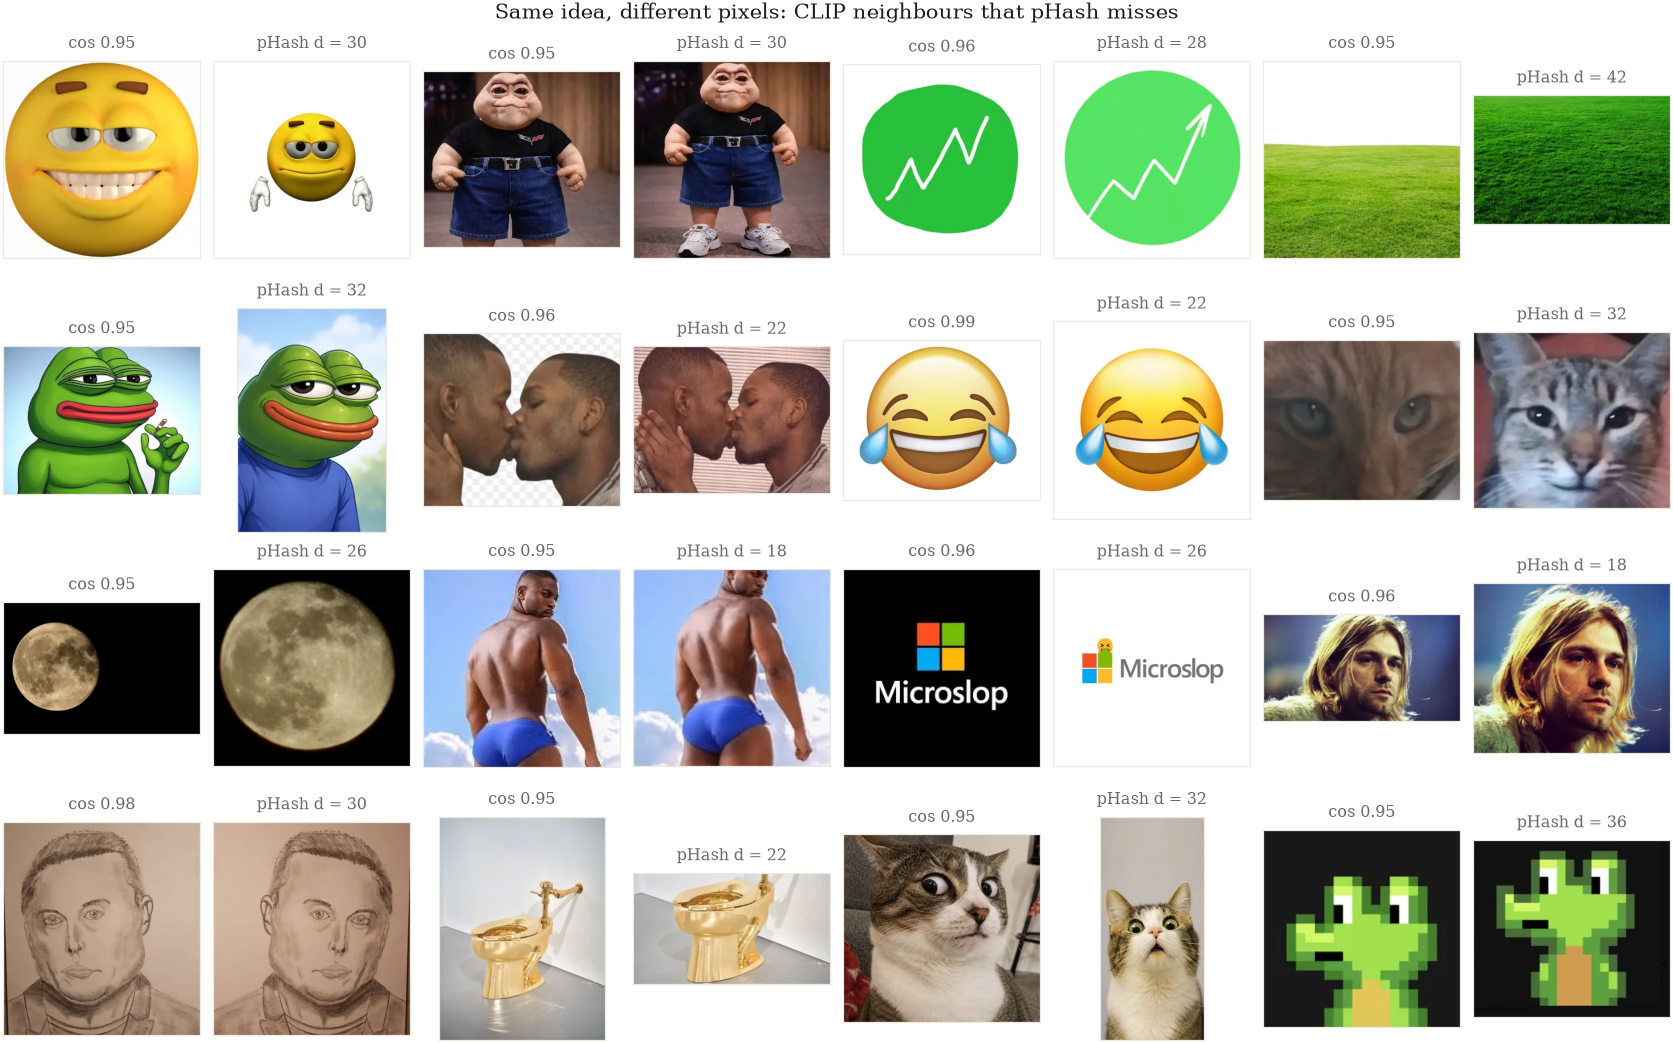

In [15]:
# "Same idea, different pixels": CLIP neighbours >= 0.95 whose pHash differs a lot
dist = np.bitwise_count(sample_ph ^ sample_ph[nn_idx])
semantic = np.flatnonzero(clip_dup & (dist > 16))
pick = np.random.default_rng(SEED).choice(semantic, size=min(16, len(semantic)), replace=False)
shas, titles = [], []
for i in pick:
    shas += [sample[i], sample[nn_idx[i]]]
    titles += [f"cos {nn_sim[i]:.2f}", f"pHash d = {dist[i]}"]
fig = show_grid(con, shas, titles, ncols=8, size=1.4, suptitle="Same idea, different pixels: CLIP neighbours that pHash misses")
save(fig, "semantic_copies")
print(f"Sample images with a CLIP neighbour >= {CLIP_DUP} but pHash distance > 16: {len(semantic) / len(X):.1%}")

## 6. Do farms stick to a theme?

For every creator wallet with at least 10 tokens, the normalised entropy of its tokens' image topics:
0 = every token in one topic, 1 = spread evenly over as many topics as it has tokens.

,count,mean,std,min,25%,50%,75%,max
size,,,,,,,,
2-10,5114.0,0.71,0.31,-0.0,0.62,0.83,0.93,1.0
11-100,45720.0,0.65,0.31,-0.0,0.47,0.77,0.88,1.0
> 100,5009.0,0.61,0.23,-0.0,0.47,0.69,0.78,1.0


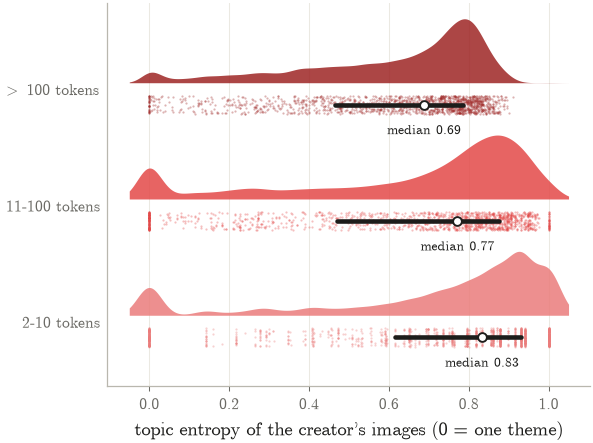

In [16]:
def norm_entropy(topics):
    p = topics.value_counts(normalize=True).to_numpy()
    k = min(len(topics), len(topic_ids))
    return float(-(p * np.log(p)).sum() / np.log(k)) if k > 1 else 0.0


busy = tok[(tok.creator_tokens >= 10) & (tok.image_topic != -1)]
ent = busy.groupby("coin_creator").agg(entropy=("image_topic", norm_entropy), size=("creator_size", "first"))
SIZES = ["2-10", "11-100", "> 100"]
fig, ax = plt.subplots(figsize=FIG_4x3)
raincloud(ax, [(f"{s} tokens", ent.loc[ent["size"] == s, "entropy"], c) for s, c in zip(SIZES, RED_RAMP[1:])],
          bw=0.1, summary_fmt="median {:.2f}")
ax.set_xlabel("topic entropy of the creator's images (0 = one theme)")
save(fig, "farm_topic_entropy")
display(ent.groupby("size", observed=True).entropy.describe().round(2))

## 7. Multimodal topics and cross-modal alignment

As in the paper, multimodal topics use the **average** of each token's image and text embeddings
(fitted on a 100k-token sample, documents = the token texts). The symmetry ratio then compares the
image-topic and multimodal-topic partitions of the same tokens, and the text topics from the
BERTopic run on names + descriptions when `TEXT_TOPICS` exists.

In [17]:
mm = tok[has].sample(SAMPLE_N, random_state=SEED)
con.register("mm_mints", mm[["mint"]])
texts = q('''SELECT m.mint, m.meta_name, m.description FROM token_metadata m JOIN mm_mints USING (mint)''')
texts = texts.drop_duplicates("mint").set_index("mint")
mm_docs = [token_text(n, d) for n, d in zip(texts.meta_name.reindex(mm.mint), texts.description.reindex(mm.mint))]
Xm = (img_emb[mm.img_row].astype(np.float32) + txt_emb[mm.txt_row].astype(np.float32)) / 2
Xm /= np.linalg.norm(Xm, axis=1, keepdims=True)

mm_model = make_topic_model()
mm_topics, _ = mm_model.fit_transform(mm_docs, embeddings=Xm)
mm_labels = {t: topic_label(mm_model, t) for t in mm_model.get_topic_info().Topic}
mm["multimodal_topic"] = mm_topics
print(f"{len(set(mm_topics)) - (-1 in mm_topics)} multimodal topics; outliers {np.mean(np.array(mm_topics) == -1):.1%}")
display(mm_model.get_topic_info().head(15)[["Topic", "Count", "Name"]])

a = mm.set_index("mint").image_topic
b = mm.set_index("mint").multimodal_topic
ratio_ib, match_ib = symmetry_ratio(a, b)
ratio_bi, _ = symmetry_ratio(b, a)
print(f"Symmetry ratio image -> multimodal: {ratio_ib:.1%}; multimodal -> image: {ratio_bi:.1%}")
mm[["mint", "image_topic", "multimodal_topic"]].to_parquet(CLIP_DIR / "token_topics_sample.parquet", index=False)

202 multimodal topics; outliers 49.2%


,Topic,Count,Name
0,-1,49201,-1_launched_discordgguxento_httpsrapidlaunchio_coin
1,0,2750,0_dog_doge_shiba_inu
2,1,1928,1_anime_desu_waifu_ai
3,2,1914,2_trump_donald_president_america
4,3,1723,3_cat_cats_kitty_meow
5,4,1484,4_live_fuing_teen_fucked
6,5,1223,5_bull_cow_black_goat
7,6,963,6_monkey_punch_ape_gorilla
8,7,857,7_labubu_mascot_domo_submarine
9,8,842,8_memes_meme_return_change


Symmetry ratio image -> multimodal: 65.2%; multimodal -> image: 66.8%


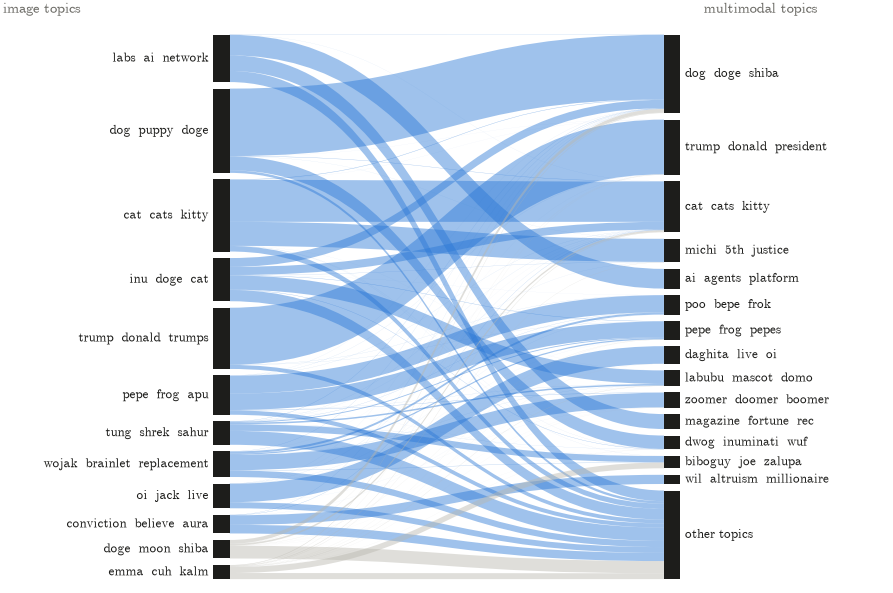

In [18]:
# Alluvial: the 12 largest image topics (in the token sample) and where their tokens go
top_left = a[a != -1].value_counts().head(12).index
flows = (pd.DataFrame({"left": a, "right": b}).query("left in @top_left and right != -1")
         .value_counts().rename("value").reset_index())
keep_right = flows.groupby("right").value.sum().sort_values(ascending=False).head(14).index
flows["right"] = np.where(flows.right.isin(keep_right), flows.right, -2)
flows = flows.groupby(["left", "right"], as_index=False).value.sum()
right_order = list(flows.groupby("right").value.sum().drop(-2, errors="ignore").sort_values(ascending=False).index)
right_order += [-2] if (flows.right == -2).any() else []
symmetric = match_ib.symmetric.to_dict()
fig, ax = plt.subplots(figsize=FIG_6x4)
alluvial(ax, flows, list(top_left), right_order,
         left_labels={t: ascii_label(image_labels[t], 28) for t in top_left},
         right_labels={**{t: ascii_label(mm_labels.get(t, ""), 28) for t in right_order}, -2: "other topics"},
         color={t: BLUE if symmetric.get(t) else MUTED for t in top_left})
ax.text(-0.45, 1.04, "image topics", fontsize=7, color=INK_2)
ax.text(1.05, 1.04, "multimodal topics", fontsize=7, color=INK_2)
save(fig, "alluvial_image_to_multimodal")

In [19]:
if TEXT_TOPICS.exists():
    text_topics = pd.read_parquet(TEXT_TOPICS).drop_duplicates("mint").set_index("mint").topic
    joined = tok.set_index("mint")
    for name, other in [("image", joined.image_topic), ("multimodal (sample)", mm.set_index("mint").multimodal_topic)]:
        r1, _ = symmetry_ratio(text_topics, other)
        r2, _ = symmetry_ratio(other, text_topics)
        print(f"text -> {name}: {r1:.1%}   {name} -> text: {r2:.1%}")
else:
    print(f"{TEXT_TOPICS} not found: export the text topics (columns mint, topic) to align them with the "
          "image and multimodal topics here.")

../data/text_topics.parquet not found: export the text topics (columns mint, topic) to align them with the image and multimodal topics here.


## 8. Takeaways

Numbers from the run on 2026-10-20 (2.7M distinct images, 5.1M tokens; graduation within 24 h).

1. **The image landscape has ~200 themes, and the token names tell what they are.** BERTopic on the
   CLIP image embeddings finds 207 topics in the 100k-image sample (46% outliers, close to BERTopic's
   usual share); centroid assignment then places 92% of all images in a topic (86% agreement with
   HDBSCAN on the sample). The paper's caption keywords describe what is drawn ("suit, tie, flag");
   keywords from the token names identify the theme (Trump, Pepe, Doge/Shiba, Wojak, Fartcoin, AI/labs
   logos, waifu/anime, penguins, Santa…).
2. **Themes differ in success.** Among the 20 largest topics the graduation rate ranges from 0.50% to
   1.51%: whale/"white trout" characters and Trump images do best (1.51%, 1.36%), some celebrity and
   streamer themes worst (≈0.5%). Self-relaunch shares range from 14% (AI/"labs" logos) to 26% (the Pepe
   topic), so some themes are far more farmed than others.
3. **Themes come in waves** (topic timelines): Doge/Shiba around the new year, Trump in late June,
   Wojak and "tung tung sahur" in short bursts, while generic themes stay flat.
4. **Matching the image to the name pays.** CLIP image-name similarity is highest for originals
   (median 0.262) and lowest for copies of a graduate (0.238), which reuse an image under a new name;
   graduation rises steadily with similarity, from 0.64% in the lowest quintile to 1.10% in the highest.
5. **Semantic copies go beyond pixel copies.** In the sample, 12% of images have a CLIP neighbour with
   cosine ≥ 0.95. Half of those (6.0% of all images) are *not* pHash near-duplicates: the same idea
   redrawn, recoloured or re-posed (gallery), and 3.9% are visually different by pHash (distance > 16)
   yet show the same thing. Replication measured by pixels (notebooks 01–02) is a lower bound.
6. **Farms are not single-theme.** The topic entropy of a creator's images is high for all sizes
   (median 0.83 for 2–10 tokens, 0.69 for 100+ tokens): farms are somewhat more focused but still
   spread over many themes, i.e. they follow whatever is trending.
7. **Image and multimodal topics largely agree.** Multimodal topics (191; averaged image + text
   embeddings, as in the paper) are sharper themes (Doge, Trump, cats, Elon, Pepe, Bitcoin, Christmas).
   The symmetry ratio is 62% (image → multimodal) and 67% (multimodal → image): most image topics have a
   mutual best match, the rest split or merge across modalities (alluvial figure).

**Content note.** Token names and topic keywords contain slurs and offensive coin names; mask them in
paper figures if needed.

**Exports for collaboration** (in `data/clip/`): `image_topics.parquet` (sha256 → topic, similarity),
`image_topic_labels.csv` (name and caption keywords), `token_topics_sample.parquet` (image and
multimodal topic per sampled token). Put the text topics in `data/text_topics.parquet` (`mint`,
`topic`) to get the text ↔ image and text ↔ multimodal symmetry ratios in section 7.